In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv("spam.csv", encoding="latin-1")
df.sample(n=5)

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
261,ham,Anyway i'm going shopping on my own now. Cos m...,NaN,NaN,NaN
209,ham,Both :) i shoot big loads so get ready!,NaN,NaN,NaN
4624,ham,I'm on the bus. Love you,NaN,NaN,NaN
482,ham,Watching tv lor...,NaN,NaN,NaN
2901,ham,"Bill, as in: Are there any letters for me. iÛ...",NaN,NaN,NaN


In [3]:
df.shape

(5572, 5)

## Data Cleaning

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   v1          5572 non-null   str  
 1   v2          5572 non-null   str  
 2   Unnamed: 2  50 non-null     str  
 3   Unnamed: 3  12 non-null     str  
 4   Unnamed: 4  6 non-null      str  
dtypes: str(5)
memory usage: 217.8 KB


In [5]:
df.drop(columns=["Unnamed: 2", "Unnamed: 3", "Unnamed: 4"], inplace=True)

In [6]:
df.rename(columns={"v1": "target", "v2": "text"}, inplace=True)

In [7]:
df.head()

,target,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [8]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df["target"] = le.fit_transform(df["target"])

In [9]:
df.head()  

,target,text
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


In [10]:
# checking for null values
df.isnull().sum() 

target    0
text      0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(403)

In [12]:
df = df.drop_duplicates(keep="first")

In [13]:
df.shape

(5169, 2)

## EDA

In [14]:
df['target'].value_counts()

target
0    4516
1     653
Name: count, dtype: int64

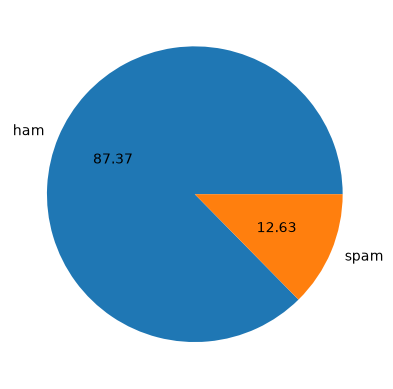

In [15]:
import matplotlib.pyplot as plt

plt.pie(df['target'].value_counts(), labels=['ham', 'spam'], autopct="%0.2f")

In [16]:
# number of characters in each text message
df['Number of characters'] = df['text'].apply(len)

In [17]:
df.head()

,target,text,Number of characters
0,0,"Go until jurong point, crazy.. Available only ...",111
1,0,Ok lar... Joking wif u oni...,29
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155
3,0,U dun say so early hor... U c already then say...,49
4,0,"Nah I don't think he goes to usf, he lives aro...",61


In [18]:
import nltk

In [19]:
nltk.download('punkt')
nltk.download('punkt_tab')

/home/pradeep/miniconda3/envs/ml/lib/python3.12/site-packages/nltk/downloader.py:1076: UserWarning: NLTK will not authorize the non-private download directory '/home/pradeep/nltk_data': it (or an ancestor) is world- or group-writable, so another local user could plant files there. Choose a private location such as ~/nltk_data.
  for msg in self.incr_download(info_or_id, download_dir, force):


[nltk_data] Downloading package punkt to /home/pradeep/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /home/pradeep/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [20]:
# number of words in each text message

df['Number of words'] = df['text'].apply(lambda x : len(nltk.word_tokenize(x)))

In [21]:
df.head()

,target,text,Number of characters,Number of words
0,0,"Go until jurong point, crazy.. Available only ...",111,24
1,0,Ok lar... Joking wif u oni...,29,8
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37
3,0,U dun say so early hor... U c already then say...,49,13
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15


In [22]:
df['Num of sentences'] = df['text'].apply(lambda x : len(nltk.sent_tokenize(x)))

In [23]:
df.head()

,target,text,Number of characters,Number of words,Num of sentences
0,0,"Go until jurong point, crazy.. Available only ...",111,24,2
1,0,Ok lar... Joking wif u oni...,29,8,2
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,2
3,0,U dun say so early hor... U c already then say...,49,13,1
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15,1


In [24]:
# ham

df[df['target'] == 0][['text', 'Number of characters', 'Number of words', 'Num of sentences']].describe()

,Number of characters,Number of words,Num of sentences
count,4516.000000,4516.000000,4516.000000
mean,70.459256,17.128432,1.820195
std,56.358207,13.504730,1.383657
min,2.000000,1.000000,1.000000
25%,34.000000,8.000000,1.000000
50%,52.000000,13.000000,1.000000
75%,90.000000,22.000000,2.000000
max,910.000000,220.000000,38.000000


In [25]:
# spam 

df[df['target'] == 1][['text', 'Number of characters', 'Number of words', 'Num of sentences']].describe()

,Number of characters,Number of words,Num of sentences
count,653.000000,653.000000,653.000000
mean,137.891271,27.672282,2.970904
std,30.137753,7.010932,1.488425
min,13.000000,2.000000,1.000000
25%,132.000000,25.000000,2.000000
50%,149.000000,29.000000,3.000000
75%,157.000000,32.000000,4.000000
max,224.000000,46.000000,9.000000


In [26]:
import seaborn as sns

<Axes: xlabel='Number of characters', ylabel='Count'>

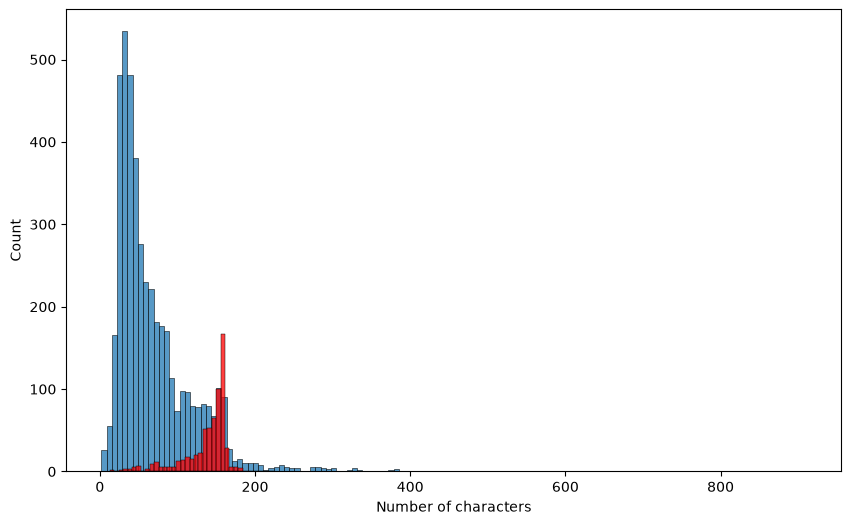

In [27]:
plt.figure(figsize=(10, 6))
sns.histplot(df[df['target'] == 0]['Number of characters'])
sns.histplot(df[df['target'] == 1]['Number of characters'], color='red')

<Axes: xlabel='Number of words', ylabel='Count'>

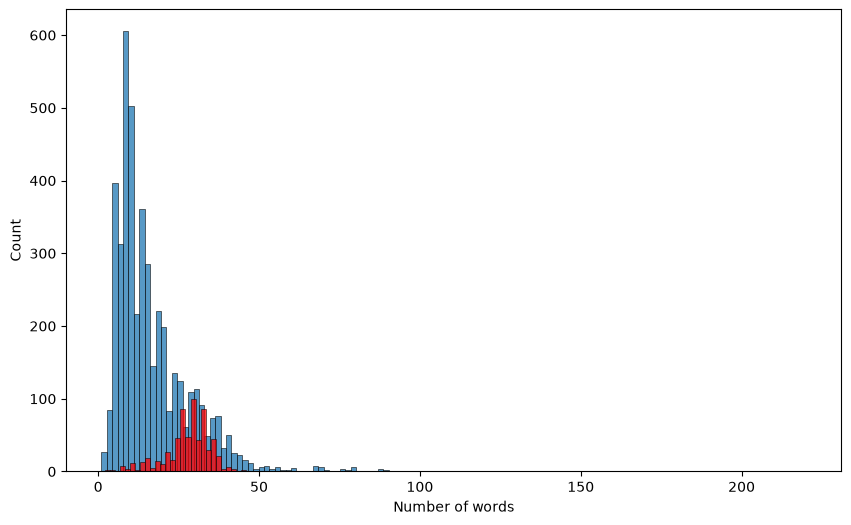

In [28]:
fig = plt.figure(figsize=(10, 6))
sns.histplot(df[df['target'] == 0]['Number of words']) 
sns.histplot(df[df['target'] == 1]['Number of words'], color='red')

<Figure size 1000x600 with 0 Axes>

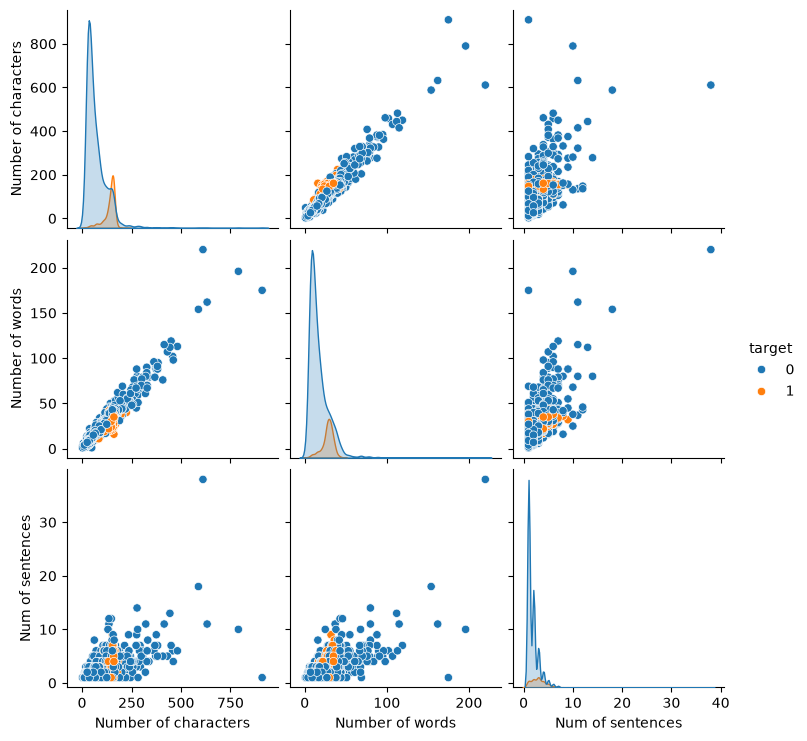

In [30]:
fig = plt.figure(figsize=(10, 6))
sns.pairplot(df, hue='target')

In [33]:
df.corr(numeric_only=True)

,target,Number of characters,Number of words,Num of sentences
target,1.000000,0.384717,0.262720,0.263939
Number of characters,0.384717,1.000000,0.965686,0.624139
Number of words,0.262720,0.965686,1.000000,0.679767
Num of sentences,0.263939,0.624139,0.679767,1.000000


<Axes: >

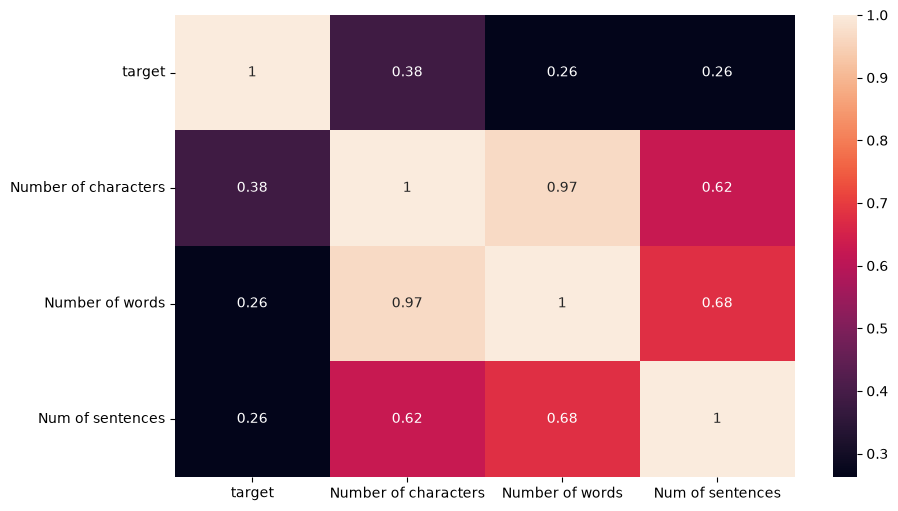

In [35]:
fig = plt.figure(figsize=(10, 6))
sns.heatmap(df.corr(numeric_only=True), annot=True)

## DataPreprocessing
- Tokenization
- Lowercase
- Removing special characters
- Removing the words and puntuations
- stemming

In [46]:
nltk.download('stopwords')
import string

/home/pradeep/miniconda3/envs/ml/lib/python3.12/site-packages/nltk/downloader.py:1076: UserWarning: NLTK will not authorize the non-private download directory '/home/pradeep/nltk_data': it (or an ancestor) is world- or group-writable, so another local user could plant files there. Choose a private location such as ~/nltk_data.
  for msg in self.incr_download(info_or_id, download_dir, force):
[nltk_data] Downloading package stopwords to
[nltk_data]     /home/pradeep/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [49]:
from nltk.stem.porter import PorterStemmer

ps = PorterStemmer()

In [55]:
def preprocess_text(text):
    text = text.lower()
    text = nltk.word_tokenize(text)

    y = []
    for i in text:
        if i.isalnum():
            y.append(i)

    text = y[:]
    y.clear()

    for i in text:
        if i not in nltk.corpus.stopwords.words('english') and i not in string.punctuation:
            y.append(i)

    text = y[:]
    y.clear()

    for i in text:
        y.append(ps.stem(i))
    return " ".join(y)

In [56]:
preprocess_text("Hello, I Loved the Machine Learning course and the content was amazing!")

'hello love machin learn cours content amaz'

In [57]:
df['transformed_text'] = df['text'].apply(preprocess_text)

In [58]:
df.head()

,target,text,Number of characters,Number of words,Num of sentences,transformed_text
0,0,"Go until jurong point, crazy.. Available only ...",111,24,2,go jurong point crazi avail bugi n great world...
1,0,Ok lar... Joking wif u oni...,29,8,2,ok lar joke wif u oni
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,2,free entri 2 wkli comp win fa cup final tkt 21...
3,0,U dun say so early hor... U c already then say...,49,13,1,u dun say earli hor u c alreadi say
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15,1,nah think goe usf live around though
